# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zilionis 2019's malignant manifold is **non-branching in geometry**: the correct
topology is a **principal curve** (ElPiGraph, non-branching by construction) fit on the
*joint* Harmony embedding — **not** a re-embedding (re-embedding an anisotropic
compartment fabricates folds). A branching PPT `tree` was tested and rejected: it
over-fragments into 3-11 spurious forks that scale with node count (noise on a
near-uniform-density roundish cloud, not one robust bifurcation), and **every tree tip
is pSom-dominant** — there is no Gast arm and no Crest arm, so there is no bifurcation
to fit.

**Scope decision (derived, not inherited).** The manifold resolves into eight lobes, but
cell cycle is **not** the lobe axis (author phase calls put cycling at ~6%, and the
smoothed cross-repression survives dropping cycling cells) and the developmental
signatures span all lobes rather than being confined to one, so the whole manifold is
the honest developmental object (Steele/Bischoff/Sun no-scoping precedent). The curve is
rooted at the **gastrulation-high** tip (developmental origin) and pseudotime flows
outward. **Note:** the biological *readout* on this trajectory (Gate 2) is evaluated in
03; here we build and root the geometry. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The
three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored
against the shared **union** control pool and graph-smoothed (3 knn-connectivity passes)
to read geography rather than inDrop per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global module means: Gast %.4f pSom %.4f Crest %.4f'
      % (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

whole malignant manifold: 3920 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.11
Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present
global module means: Gast -0.0092 pSom 0.0386 Crest -0.0225


### Scope decision — whole manifold vs a single lobe (data-driven)
Test whether the developmental axis is confined to one lobe (Kürten case, scoping
justified) or spans all (Bischoff/Sun/Steele case, keep whole manifold). The lobes carry
near-identical smoothed developmental means and the Crest-high decile is distributed
across lobes. Because Gast is mildly cell-cycle-confounded (01), the robustness test uses
the **conservative** continuous cycling call (score>0.1, ~35% of cells — far more than
the ~6% phase-only count) rather than the lenient phase set: the smoothed module
cross-repression **survives removing that entire cycling third** (each pairwise r shifts by
≤ 0.03: −0.53/−0.51/−0.36 → −0.54/−0.48/−0.38), so proliferation is orthogonal to (and
does not define) the developmental structure. The whole manifold is carried forward (no
scoping).

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cycling']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'lobe'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distributed across lobes:', frac)
# quantify the Gast cell-cycle confound now that modules are scored (flagged in 01)
from scipy.stats import pearsonr as _pr
_cyc = adata.obs['cycle_score'].values
print('\nper-cell module vs cell-cycle-score confound:')
for m in ['Gast','pSom','Crest']:
    print('  r(%s, cycle_score) = %+.3f' % (m, _pr(adata.obs[m].values, _cyc)[0]))
# cross-repression with cycling cells removed (conservative: score>0.1, ~36%, not the ~6% phase set)
nc = ~adata.obs['cycling_score'].values
print('\nsmoothed cross-repression, conservative cycling set removed (score>0.1; n_kept=%d):' % nc.sum())
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a].values[nc], adata.obs[b].values[nc])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('-> developmental structure is orthogonal to the (low, non-partitioning) cell cycle; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.53
  Crest_sm vs Gast_sm: r = -0.51
  Crest_sm vs pSom_sm: r = -0.36

per-lobe smoothed developmental means:
      Gast_sm  pSom_sm  Crest_sm  cycling
lobe                                     
0     -0.0248   0.0475   -0.0220   0.0229
1     -0.0023   0.0408   -0.0288   0.0474
2     -0.0143   0.0371   -0.0147   0.0264
3     -0.0029   0.0312   -0.0167   0.1073
4     -0.0055   0.0282   -0.0204   0.0000
5      0.0085   0.0329   -0.0286   0.1523
6     -0.0089   0.0296   -0.0193   0.0440
7     -0.0012   0.0404   -0.0284   0.0753

Crest-high decile distributed across lobes: {'2': 0.59, '3': 0.35, '0': 0.03, '6': 0.03, '5': 0.0, '1': 0.0, '4': 0.0, '7': 0.0}

per-cell module vs cell-cycle-score confound:
  r(Gast, cycle_score) = +0.176
  r(pSom, cycle_score) = -0.053
  r(Crest, cycle_score) = -0.085

smoothed cross-repression, conservative cycling set removed (score>0.1; n_kept=2501):
  Gast_sm vs pSom_sm: r = -0

### Topology — curve vs tree, read from the embedding
Before fitting, we confirm the topology honestly. A PPT `tree` is scanned across node
counts and regularisations: the tip/fork count is unstable (a bush at weak
regularisation collapsing to a line at strong), and where a clean 3-tip Y does emerge,
**all three tips are pSom-dominant** — the fork is not a Gast/pSom co-expression hub and
there is no Gast or Crest arm. A roundish cloud with no reproducible hub-and-two-arms is
a **non-branching** manifold: the principal curve is the correct model (matching the
scFates method to the topology, per the eval rule).

In [5]:
with contextlib.redirect_stdout(io.StringIO()):
    tscan = []
    for N in [50,100,150]:
        at = sub.copy()
        scf.tl.tree(at, method='ppt', Nodes=N, ppt_lambda=100, ppt_sigma=0.3,
                    use_rep='X_pca_harmony', seed=SEED, plot=False)
        B = np.asarray(at.uns['graph']['B']); deg=(B>0).sum(0)
        tscan.append((N, int((deg==1).sum()), int((deg>=3).sum())))
print('PPT tree tip/fork scan (transcriptome rep):')
for N,t,f in tscan: print(f'  Nodes={N}: {t} tips, {f} forks')
# tip identity of the strongest-regularised tree
with contextlib.redirect_stdout(io.StringIO()):
    at = sub.copy()
    scf.tl.tree(at, method='ppt', Nodes=150, ppt_lambda=200, ppt_sigma=0.3,
                use_rep='X_pca_harmony', seed=SEED, plot=False)
B = np.asarray(at.uns['graph']['B']); R = np.asarray(at.obsm['X_R']); deg=(B>0).sum(0)
tips = np.where(deg==1)[0]
print('\nclean-tree tip module profiles (all pSom-dominant -> no Gast/Crest arm):')
for tp in tips:
    w = R[:,tp]
    print(f'  tip {tp}: Gast={np.average(at.obs.Gast,weights=w):+.3f} '
          f'pSom={np.average(at.obs.pSom,weights=w):+.3f} '
          f'Crest={np.average(at.obs.Crest,weights=w):+.3f}')
print('-> no reproducible hub-and-two-arms; topology is non-branching -> fit a principal curve.')

PPT tree tip/fork scan (transcriptome rep):
  Nodes=50: 3 tips, 1 forks
  Nodes=100: 5 tips, 3 forks
  Nodes=150: 4 tips, 2 forks

clean-tree tip module profiles (all pSom-dominant -> no Gast/Crest arm):
  tip 0: Gast=-0.024 pSom=+0.053 Crest=-0.025
  tip 22: Gast=-0.001 pSom=+0.027 Crest=-0.019
  tip 30: Gast=-0.018 pSom=+0.038 Crest=-0.011
  tip 118: Gast=-0.005 pSom=+0.041 Crest=-0.028
-> no reproducible hub-and-two-arms; topology is non-branching -> fit a principal curve.


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median edge
length) certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth. The `assert` fails loudly if the curve forks or
folds.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.46 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin (Crest is developmentally *late*, so it does not root the trajectory; nor does a
proliferation state). Pseudotime then flows away from it. (Whether that flow reproduces
the required Gast/pSom-origin -> terminal-Crest order is the Gate-2 question, answered in
03.)

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    cyc = sub.obs['cycling'].values[m].mean()
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean(), cyc)
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} cycling={cyc:.2%}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low; developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0214 pSom=+0.0440 Crest=-0.0193 cycling=2.54%
tip 2: Gast=-0.0005 pSom=+0.0309 Crest=-0.0211 cycling=10.61%
derived root = tip 2 (Gast/pSom-high, Crest-low; developmental origin)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.585 p=0.0e+00
  pSom_sm: rho=+0.764 p=0.0e+00
  Crest_sm: rho=+0.018 p=2.6e-01
  cyc_score: rho=-0.024 p=1.3e-01


### Reorient to house style (pseudotime left -> right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD basis
can silently reflect an axis). We rotate the embedding so pseudotime runs along the
horizontal, then flip so low pseudotime lands on the left. The assertion confirms the
orientation. This keeps every downstream panel in a consistent left->right pseudotime
layout.

In [8]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
# rotate so the pseudotime axis is horizontal: principal axis of (xy weighted by pt gradient)
from numpy.linalg import svd as _svd
c = xy - xy.mean(0)
# direction that best aligns with pseudotime
w = (t - t.mean())
dirv = (c * w[:,None]).sum(0); dirv = dirv/np.linalg.norm(dirv)
ang = np.arctan2(dirv[1], dirv[0])
Rm = np.array([[np.cos(-ang),-np.sin(-ang)],[np.sin(-ang),np.cos(-ang)]])
xyr = c @ Rm.T
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: rotated to horizontal; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: rotated to horizontal; corr(x_lin, pseudotime) = +0.89


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf (curve edges overlaid; fold self-approach 2.46)


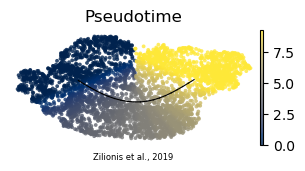

In [9]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
# persist the curve node coordinates (raw umap) for rendering the actual curve edges
sub.uns['curve_B'] = np.asarray(sub.uns['graph']['B'])
sub.uns['curve_F'] = np.asarray(sub.uns['graph']['F'])
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
# overlay the actual curve edges (rotated into the linear layout) to show fold-freeness
Braw = sub.uns['curve_B']; Fraw = sub.uns['curve_F'].T
Fc = (Fraw - xy.mean(0)) @ Rm.T
if float(np.corrcoef((c @ Rm.T)[:,0], t)[0,1]) < 0: Fc[:,0] = -Fc[:,0]
ii,jj = np.where(np.triu(Braw>0))
for i,j in zip(ii,jj):
    ax.plot([Fc[i,0],Fc[j,0]],[Fc[i,1],Fc[j,1]],'-',c='k',lw=0.8,zorder=5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf (curve edges overlaid; fold self-approach %.2f)' % sa)